# Fase 6 · Análisis, validación y storytelling (continuación)

### Configuración
Misma celda de configuración que la Fase 3: rutas, importaciones y funciones auxiliares. Requiere que este notebook esté dentro de su carpeta de fase, con `src/`, `datos/` y `reports/` en la raíz del repositorio.

In [ ]:
# ---------------------------------------------------------------------------
# Configuración, rutas e importaciones
# ---------------------------------------------------------------------------
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# Respaldo de visualización: el notebook funciona con o sin IPython instalado.
try:
    from IPython.display import SVG, display
    _TIENE_IPYTHON = True
except ImportError:  # pragma: no cover
    _TIENE_IPYTHON = False

    def display(*args, **kwargs):
        pass

    class SVG:  # marcador de posición para poder usar display(SVG(...))
        def __init__(self, datos):
            self.datos = datos

RAIZ = Path.cwd()
if not (RAIZ / "src").exists() and (RAIZ.parent / "src").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

import graficos_svg as g   # librería de gráficos SVG del proyecto

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

RUTA_DATOS = RAIZ / "datos"
RUTA_REPORTES = RAIZ / "reports"
RUTA_GRAFICOS = RAIZ / "graficos"
RUTA_GRAFICOS.mkdir(exist_ok=True)
DIR_ENTREGA = RAIZ / "entrega"
DIR_ENTREGA.mkdir(exist_ok=True)

print(f"Raíz del proyecto : {RAIZ}")
print(f"IPython disponible: {_TIENE_IPYTHON}")
print(f"pandas {pd.__version__} · numpy {np.__version__}")


def mostrar(svg: str, nombre: str | None = None) -> None:
    """Renderiza un SVG en el notebook y, si se indica, lo exporta a graficos/."""
    if nombre:
        (RUTA_GRAFICOS / f"{nombre}.svg").write_text(svg, encoding="utf-8")
    if _TIENE_IPYTHON:
        display(SVG(svg))
    else:
        print(f"[gráfico {nombre or 'sin nombre'}: {len(svg):,} caracteres SVG]")


def tabla_md(df: pd.DataFrame, dec: int = 2) -> str:
    """Convierte un DataFrame en tabla Markdown (sin depender de tabulate)."""
    enc = [str(c) for c in df.columns]
    filas = []
    for _, r in df.iterrows():
        vals = []
        for v in r:
            if isinstance(v, (int, np.integer)):
                vals.append(f"{v:,}")
            elif isinstance(v, (float, np.floating)):
                vals.append(f"{v:,.{dec}f}")
            else:
                vals.append(str(v))
        filas.append(vals)
    lineas = ["| " + " | ".join(enc) + " |",
              "|" + "|".join(["---"] * len(enc)) + "|"]
    lineas += ["| " + " | ".join(f) + " |" for f in filas]
    return "\n".join(lineas)

### Carga de resultados del pipeline

In [ ]:
# Carga del consolidado estadístico generado por el pipeline (src/analisis_retail.py)
with open(RUTA_REPORTES / "analisis_completo.json", encoding="utf-8") as fh:
    R = json.load(fh)
print("Consolidado cargado:", ", ".join(R.keys()))

## 11. Proyección 2019

La proyección se construye con un modelo **log-lineal con índice estacional**:
se ajusta `ln(Ventas mensuales) = β₀ + β₁·t` sobre los 36 meses de 2016-2018 —se
excluye 2015 porque es un año con ticket atípicamente alto que sesga la tendencia—
y se multiplica la tendencia por el índice estacional mensual estimado con los
residuos. Se reporta además un **escenario conservador** que anualiza la velocidad
de venta observada al cierre de 2018, útil como cota inferior defendible.

In [27]:
# ---------------------------------------------------------------------------
# 11.1 Modelo, coeficientes y escenarios
# ---------------------------------------------------------------------------
pry = R["proyeccion"]
print(f"Muestra de ajuste : {pry['muestra_ajuste']}")
print(f"R² = {pry['r2_serie_mensual']:.4f} · R² ajustado = {pry['r2_ajustado']:.4f}")
print(f"Crecimiento mensual estimado: {pry['crecimiento_mensual_estimado']*100:.2f} % "
      f"(IC 95 %: [{pry['ic95_crecimiento_mensual'][0]*100:.2f} %; {pry['ic95_crecimiento_mensual'][1]*100:.2f} %])")
print(f"Equivalente anual: {pry['crecimiento_anual_equivalente']*100:.2f} %")
print(f"Sensibilidad con los 48 meses: pendiente anual "
      f"{pry['sensibilidad_48_meses']['crecimiento_anual_equivalente']*100:.2f} % · "
      f"R² {pry['sensibilidad_48_meses']['r2']:.4f}")
print()
print("Coeficientes del modelo de ingresos:")
m = pry["modelo_log_lineal"]
for v, c, e, t, p in zip(m["variables"], m["coeficientes"], m["errores_standard"] if "errores_standard" in m else m["errores_estandar"], m["t"], m["p_valores"]):
    print(f"  {v:<12} coef = {c:>10.5f} · ee = {e:>8.5f} · t = {t:>8.3f} · p = {p:.3e}")
print()
proy = pd.DataFrame(pry["proyeccion_2019"])
print("Proyección mensual 2019:")
print(proy[["AnioMes", "Mes", "VentasProyectadas", "PedidosProyectados", "TicketProyectado", "IndiceEstacional"]]
      .round(2).to_string(index=False))
print()
eb = pry["escenario_base_anualizacion"]
print("Comparación de escenarios 2019")
escenarios = pd.DataFrame([
    ("Real 2018", pry["total_2018_real"]),
    ("Escenario conservador: anualiza 2.º semestre 2018", eb["anualizado_segundo_semestre_2018"]),
    ("Escenario base: anualiza el cierre de 2018 (Q4)", eb["anualizado_q4_2018"]),
    ("Modelo log-lineal + estacionalidad", pry["total_2019_proyectado"]),
], columns=["Escenario", "Ingresos 2019 (USD)"])
escenarios["Variación vs. 2018"] = (escenarios["Ingresos 2019 (USD)"] / pry["total_2018_real"] - 1).map(lambda v: f"{v*100:+.1f} %")
escenarios["Ingresos 2019 (USD)"] = escenarios["Ingresos 2019 (USD)"].map(lambda v: f"{v:,.0f}")
display(escenarios)

Muestra de ajuste : 2016-01 a 2018-12 (36 meses)
R² = 0.3694 · R² ajustado = 0.3508
Crecimiento mensual estimado: 3.12 % (IC 95 %: [1.73 %; 4.52 %])
Equivalente anual: 44.54 %
Sensibilidad con los 48 meses: pendiente anual 31.63 % · R² 0.2669

Coeficientes del modelo de ingresos:
  intercepto   coef =   10.14220 · ee =  0.14020 · t =   72.355 · p = 7.938e-39
  t            coef =    0.03070 · ee =  0.00690 · t =    4.462 · p = 8.451e-05

Proyección mensual 2019:
AnioMes Mes  VentasProyectadas  PedidosProyectados  TicketProyectado  IndiceEstacional
2019-01 Ene        47,808.6800            109.5000          436.7700            0.6200
2019-02 Feb        34,566.9100             79.2000          436.3300            0.4400
2019-03 Mar        88,684.1300            203.5000          435.8900            1.0900
2019-04 Abr        72,054.1300            165.5000          435.4600            0.8600
2019-05 May        83,341.6800            191.6000          435.0200            0.9600
2019-06 Jun

,Escenario,Ingresos 2019 (USD),Variación vs. 2018
0,Real 2018,"722,052",+0.0 %
1,Escenario conservador: anualiza 2.º semestre 2018,"1,007,982",+39.6 %
2,Escenario base: anualiza el cierre de 2018 (Q4),"1,168,070",+61.8 %
3,Modelo log-lineal + estacionalidad,"1,128,320",+56.3 %


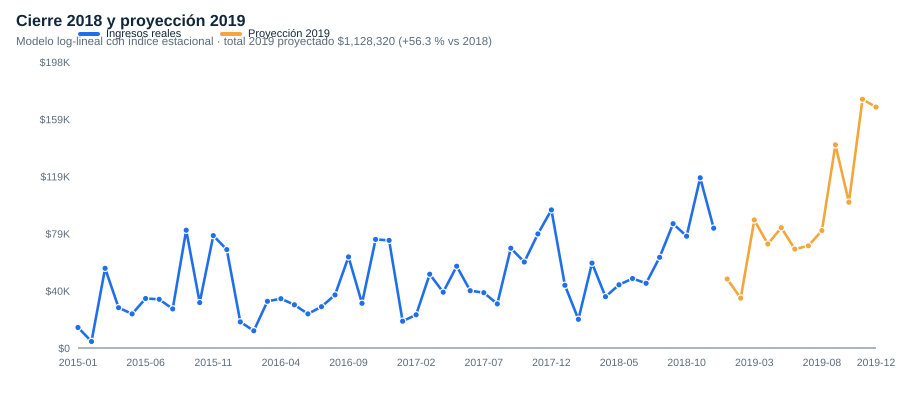

El pico proyectado sigue ubicándose en nov-dic 2019 (172,354 USD y 166,918 USD respectivamente).


In [28]:
# ---------------------------------------------------------------------------
# 11.2 Visualización de la proyección
# ---------------------------------------------------------------------------
hist = pd.DataFrame(R["series"]["mensual"])[["AnioMes", "Ventas"]]
proy_serie = proy[["AnioMes", "VentasProyectadas"]].rename(columns={"VentasProyectadas": "Ventas"})
combinado = pd.concat([hist, proy_serie], ignore_index=True)
combinado["Serie"] = ["Real"] * len(hist) + ["Proyectado"] * len(proy_serie)

mostrar(
    g.linea(
        combinado["AnioMes"].tolist(),
        {"Ingresos reales": [v if s == "Real" else None for v, s in zip(combinado["Ventas"], combinado["Serie"])],
         "Proyección 2019": [v if s == "Proyectado" else None for v, s in zip(combinado["Ventas"], combinado["Serie"])]},
        "Cierre 2018 y proyección 2019",
        f"Modelo log-lineal con índice estacional · total 2019 proyectado "
        f"{g.dinero(pry['total_2019_proyectado'])} ({pry['variacion_proyectada']*100:+.1f} % vs 2018)",
        colores={"Ingresos reales": g.PALETA["primario"], "Proyección 2019": g.PALETA["acento"]}),
    "20_proyeccion_2019")

print(f"El pico proyectado sigue ubicándose en nov-dic 2019 "
      f"({proy.loc[proy.Mes == 'Nov', 'VentasProyectadas'].iat[0]:,.0f} USD y "
      f"{proy.loc[proy.Mes == 'Dic', 'VentasProyectadas'].iat[0]:,.0f} USD respectivamente).")